# Compare two versions of the filtered Dynamic Bayesian Network - June 9, 2016
## Initializations

In [1]:
%pylab inline
import os
from collections import defaultdict
import pandas as pd
from matplotlib_venn import venn2_unweighted

# Tony's version
dbn_t_file = os.path.join('..','..','evaluation','2016-05-03-DBN-TXN-TPS-networks','DBN.tsv')
# Ali's version
dbn_a_file = os.path.join('..','..','evaluation','2016-05-03-DBN-TXN-TPS-networks','DBN-filtered-edgelist.tsv')

Populating the interactive namespace from numpy and matplotlib


## Helper function to load the network
Used for Tony's verison.  Optionally sort the nodes by their names instead of keeping the original DBN direction.

In [2]:
def load_dbn(dbn_file, sort=False):
    # Create a mapping of directed protein-protein edges to their max probability
    dir_edges = defaultdict(float)
    self_count = 0
    
    with open(dbn_file) as dbn_f:
        # Skip the header
        dbn_f.readline()
        for line in dbn_f:
            # protein 1 \t protein 2 \t probability \t sign \t peptide 1 \t peptide 2
            parts = line.strip().split('\t')
            # Ignore self-edges, which occur when a multiple peptides map to a protein
            if (not parts[0] == parts[1]):
                if sort:
                    sorted_prots = sorted((parts[0], parts[1]))
                    edge = '%s:d:%s' % (sorted_prots[0], sorted_prots[1])
                    dir_edges[edge] = max(dir_edges[edge], float(parts[2]))
                else:
                    edge = '%s:d:%s' % (parts[0], parts[1])
                    dir_edges[edge] = max(dir_edges[edge], float(parts[2]))
            else:
                self_count +=1 
        
    # Create a data frame
    df = pd.DataFrame(data=dir_edges.items(), columns=['Edges', 'Probabilities'])
    print 'Loaded %d edges from Dynamic Bayesian Network, ignored %d self-edges' % (len(df), self_count)
    return df

## Load both versions of the network
Try loading Tony's version with edge directions and with undirected edges

In [3]:
dbn_thresh = 0.025
dbn_dir_t_df = load_dbn(dbn_t_file, False)
dbn_dir_thresh_t_df = dbn_dir_t_df[dbn_dir_t_df['Probabilities'] >= dbn_thresh]
print 'Tony: %d directed DBN edges with probability >= %s' % (len(dbn_dir_thresh_t_df), str(dbn_thresh))
print

dbn_thresh = 0.025
dbn_undir_t_df = load_dbn(dbn_t_file, True)
dbn_undir_thresh_t_df = dbn_undir_t_df[dbn_undir_t_df['Probabilities'] >= dbn_thresh]
print 'Tony: %d undirected DBN edges with probability >= %s' % (len(dbn_undir_thresh_t_df), str(dbn_thresh))
print

dbn_a_set = set()
with open(dbn_a_file) as dfile:
    for line in dfile:
        parts = line.strip().split()
        assert len(parts) == 2
        dbn_a_set.add(parts[0] + ':d:' + parts[1])
print 'Ali: %d DBN edges' % (len(dbn_a_set))

Loaded 490700 edges from Dynamic Bayesian Network, ignored 0 self-edges
Tony: 587 directed DBN edges with probability >= 0.025

Loaded 245350 edges from Dynamic Bayesian Network, ignored 0 self-edges
Tony: 572 undirected DBN edges with probability >= 0.025

Ali: 572 DBN edges


## Find the extra edges in Tony's version
This version of Ali's network has sorted node names, not the original edge direction.  That is why only 281 edges intersect.  Loading Tony's version with sort=True (undirected edges) will give identical networks with 572 edges.

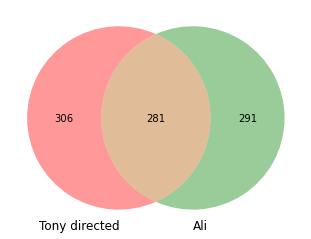

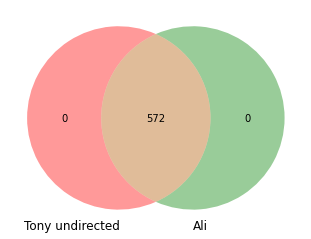

In [4]:
venn2_unweighted([set(dbn_dir_thresh_t_df['Edges']), dbn_a_set], ['Tony directed', 'Ali']);

figure()
venn2_unweighted([set(dbn_undir_thresh_t_df['Edges']), dbn_a_set], ['Tony undirected', 'Ali']);